# 03 · Focos de calor en la Altillanura (NASA FIRMS – MODIS)

**Fuente:** NASA FIRMS, MODIS Colección 6.1, detecciones de fuego activo
en Colombia, 2000–2025.

**Propósito:** filtrar las detecciones dentro de los 7 municipios y
construir la serie mensual de focos de calor por municipio.

**Nota:** cada punto es un píxel caliente, no un incendio. Se habla de
"detecciones" o "focos", no de "número de incendios".

**Salidas:**
- `datos/procesados/firms_altillanura_puntos.gpkg` (puntos filtrados)
- `datos/procesados/firms_mensual_municipio.csv` (serie mensual)

## Paso 1. Preparar el entorno

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

RUTA = '/content/drive/MyDrive/proyecto-altillanura-STDG'
CRUDOS = f'{RUTA}/datos/crudos'
PROCESADOS = f'{RUTA}/datos/procesados'
FIGURAS = f'{RUTA}/resultados/figuras'

import os, glob, zipfile
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

print('Entorno listo')

Mounted at /content/drive
Entorno listo


## Paso 2. Leer y unir los archivos anuales

In [ ]:
carpeta = f'{CRUDOS}/firms/FIRMS_MODIS'

archivos = sorted(glob.glob(f'{carpeta}/*.csv'))
print('Archivos CSV encontrados:', len(archivos))
for a in archivos:
    print('  ', os.path.basename(a))

partes = [pd.read_csv(a, dtype={'acq_time': str}) for a in archivos]
firms = pd.concat(partes, ignore_index=True)
firms['acq_date'] = pd.to_datetime(firms['acq_date'])

print('\nDetecciones en Colombia:', f'{len(firms):,}')
print('Desde', firms['acq_date'].min().date(), 'hasta', firms['acq_date'].max().date())

por_anio = firms.groupby(firms['acq_date'].dt.year).size()
print('\nDetecciones por año (Colombia):')
print(por_anio.to_string())

Archivos CSV encontrados: 26
   modis_2000_Colombia.csv
   modis_2001_Colombia.csv
   modis_2002_Colombia.csv
   modis_2003_Colombia.csv
   modis_2004_Colombia.csv
   modis_2005_Colombia.csv
   modis_2006_Colombia.csv
   modis_2007_Colombia.csv
   modis_2008_Colombia.csv
   modis_2009_Colombia.csv
   modis_2010_Colombia.csv
   modis_2011_Colombia.csv
   modis_2012_Colombia.csv
   modis_2013_Colombia.csv
   modis_2014_Colombia.csv
   modis_2015_Colombia.csv
   modis_2016_Colombia.csv
   modis_2017_Colombia.csv
   modis_2018_Colombia.csv
   modis_2019_Colombia.csv
   modis_2020_Colombia.csv
   modis_2021_Colombia.csv
   modis_2022_Colombia.csv
   modis_2023_Colombia.csv
   modis_2024_Colombia.csv
   modis_2025_Colombia.csv

Detecciones en Colombia: 675,817
Desde 2000-11-01 hasta 2025-12-31

Detecciones por año (Colombia):
acq_date
2000     1372
2001    13868
2002    17733
2003    38900
2004    45648
2005    27991
2006    24015
2007    44691
2008    27140
2009    26675
2010    24156
2011 

## Paso 3. Limpiar las detecciones
- `type = 0`: solo fuego en vegetación (excluye fuentes fijas y volcanes).
- `confidence >= 30`: descarta detecciones de confianza baja.
- Se eliminan registros duplicados.

In [ ]:
n_inicial = len(firms)

firms = firms[firms['type'] == 0]
n_tipo = len(firms)

firms = firms[firms['confidence'] >= 30]
n_conf = len(firms)

firms = firms.drop_duplicates(
    subset=['latitude', 'longitude', 'acq_date', 'acq_time', 'satellite'])
n_final = len(firms)

print(f'Inicial:                    {n_inicial:>10,}')
print(f'Tras filtrar tipo = 0:      {n_tipo:>10,}  (-{n_inicial - n_tipo:,})')
print(f'Tras filtrar confianza>=30: {n_conf:>10,}  (-{n_tipo - n_conf:,})')
print(f'Tras quitar duplicados:     {n_final:>10,}  (-{n_conf - n_final:,})')

Inicial:                       675,817
Tras filtrar tipo = 0:         669,357  (-6,460)
Tras filtrar confianza>=30:    637,202  (-32,155)
Tras quitar duplicados:        637,202  (-0)


## Paso 4. Unión espacial con los 7 municipios
Cada punto se asigna al municipio que lo contiene, usando la capa
base de la fase 1 (EPSG:9377).

In [ ]:
mpios = gpd.read_file(f'{PROCESADOS}/altillanura_municipios.gpkg')

# Prefiltro rápido con el rectángulo de la Altillanura (en grados)
xmin, ymin, xmax, ymax = mpios.to_crs(4326).total_bounds
firms = firms[firms['longitude'].between(xmin, xmax) &
              firms['latitude'].between(ymin, ymax)]

puntos = gpd.GeoDataFrame(
    firms,
    geometry=gpd.points_from_xy(firms['longitude'], firms['latitude']),
    crs=4326).to_crs(9377)

puntos = gpd.sjoin(
    puntos, mpios[['mpio_cdpmp', 'mpio_cnmbr', 'dpto_cnmbr', 'geometry']],
    predicate='within', how='inner').drop(columns='index_right')

print('Detecciones dentro de la Altillanura:', f'{len(puntos):,}')
print('\nPor municipio:')
print(puntos['mpio_cnmbr'].value_counts().to_string())

print('\nDetecciones por año y satélite:')
print(puntos.groupby([puntos['acq_date'].dt.year, 'satellite'])
      .size().unstack(fill_value=0).to_string())

Detecciones dentro de la Altillanura: 220,432

Por municipio:
mpio_cnmbr
CUMARIBO          68279
PUERTO GAITÁN     49366
LA PRIMAVERA      42393
MAPIRIPÁN         21367
PUERTO CARREÑO    20883
SANTA ROSALÍA      9730
PUERTO LÓPEZ       8414

Detecciones por año y satélite:
satellite  Aqua  Terra
acq_date              
2000          0    892
2001          0   5203
2002       1878   5793
2003       6004   5006
2004       7148   6734
2005       5428   4149
2006       3970   3538
2007       7030   6524
2008       4802   4766
2009       4535   4053
2010       5076   4205
2011       3980   3280
2012       3959   3363
2013       4442   4068
2014       4881   4794
2015       3752   2878
2016       5118   4327
2017       4786   3488
2018       4911   4474
2019       3980   3034
2020       5772   4568
2021       4233   3121
2022       5278   4834
2023       4229   3337
2024       5129   2904
2025       4298   2480


## Paso 5. Serie mensual por municipio
Se cuentan las detecciones por municipio y mes. Los meses sin
detecciones se completan con 0, para que la serie no tenga huecos.

In [ ]:
puntos['mes'] = puntos['acq_date'].dt.to_period('M')

meses = pd.period_range('2000-11', '2025-12', freq='M')
indice = pd.MultiIndex.from_product(
    [sorted(mpios['mpio_cdpmp']), meses], names=['mpio_cdpmp', 'mes'])

total = (puntos.groupby(['mpio_cdpmp', 'mes']).size()
         .reindex(indice, fill_value=0).rename('focos_total'))
terra = (puntos[puntos['satellite'] == 'Terra']
         .groupby(['mpio_cdpmp', 'mes']).size()
         .reindex(indice, fill_value=0).rename('focos_terra'))

mensual = pd.concat([total, terra], axis=1).reset_index()
mensual = mensual.merge(mpios[['mpio_cdpmp', 'mpio_cnmbr']], on='mpio_cdpmp')

print('Filas:', len(mensual), '| municipios:', mensual['mpio_cdpmp'].nunique(),
      '| meses:', mensual['mes'].nunique())
mensual.head(15)

Filas: 2114 | municipios: 7 | meses: 302


,mpio_cdpmp,mes,focos_total,focos_terra,mpio_cnmbr
0,50325,2000-11,19,19,MAPIRIPÁN
1,50325,2000-12,31,31,MAPIRIPÁN
2,50325,2001-01,150,150,MAPIRIPÁN
3,50325,2001-02,175,175,MAPIRIPÁN
4,50325,2001-03,79,79,MAPIRIPÁN
5,50325,2001-04,6,6,MAPIRIPÁN
6,50325,2001-05,0,0,MAPIRIPÁN
7,50325,2001-06,1,1,MAPIRIPÁN
8,50325,2001-07,5,5,MAPIRIPÁN
9,50325,2001-08,1,1,MAPIRIPÁN


## Paso 6. Serie mensual y perfil estacional de la Altillanura

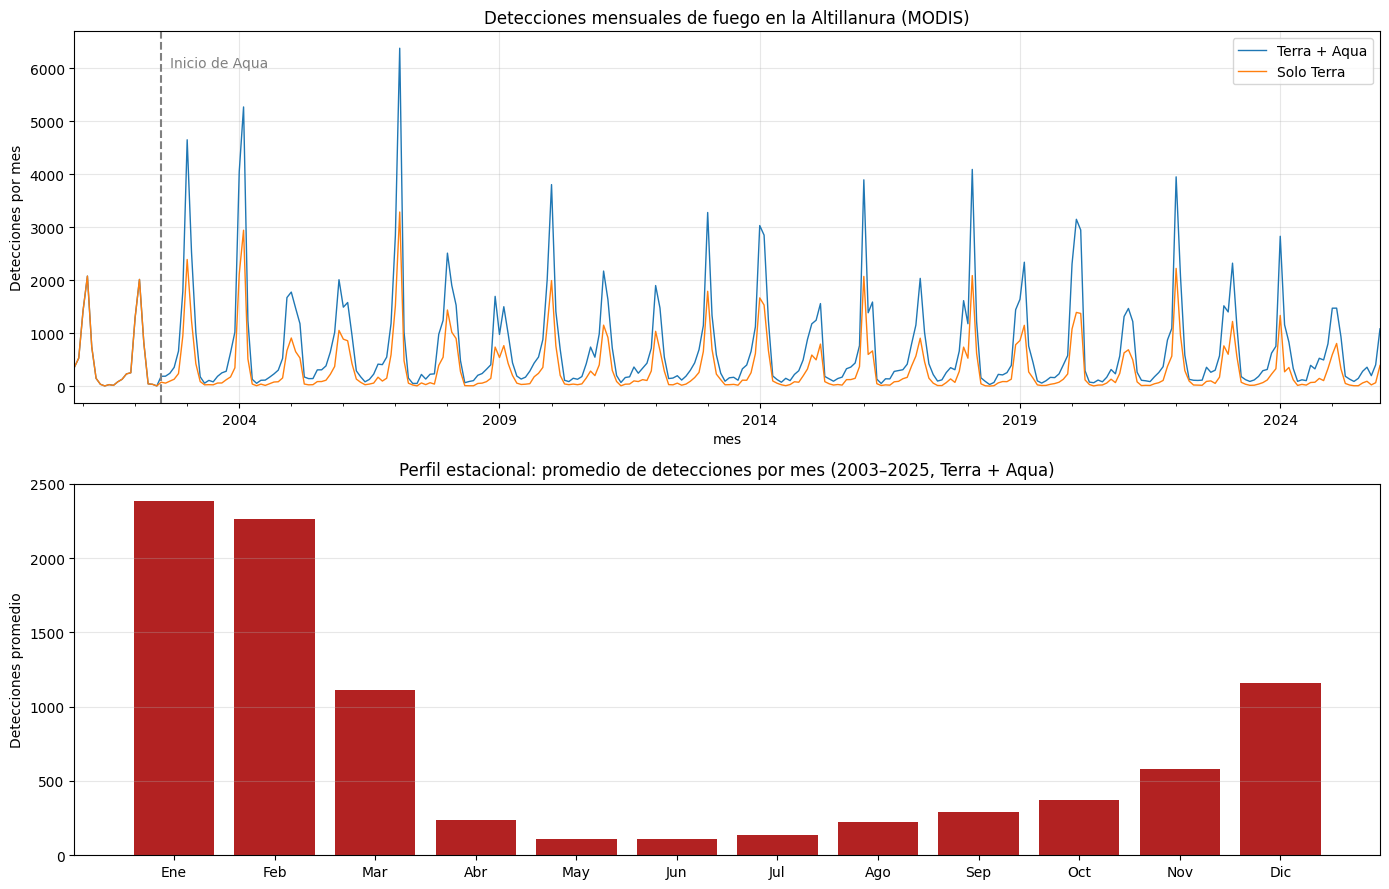

Participación de diciembre a marzo en el total: 77%


In [ ]:
region = mensual.groupby('mes')[['focos_total', 'focos_terra']].sum()
region.index = region.index.to_timestamp()

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# (a) Serie mensual
region['focos_total'].plot(ax=axes[0], label='Terra + Aqua', linewidth=1)
region['focos_terra'].plot(ax=axes[0], label='Solo Terra', linewidth=1)
axes[0].axvline(pd.Timestamp('2002-07-01'), color='gray', linestyle='--')
axes[0].text(pd.Timestamp('2002-09-01'), axes[0].get_ylim()[1] * 0.9,
             'Inicio de Aqua', color='gray')
axes[0].set_title('Detecciones mensuales de fuego en la Altillanura (MODIS)')
axes[0].set_ylabel('Detecciones por mes')
axes[0].legend()
axes[0].grid(alpha=0.3)

# (b) Perfil estacional: promedio por mes del año (2003–2025)
estacional = region.loc['2003':, 'focos_total']
perfil = estacional.groupby(estacional.index.month).mean()
nombres = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun',
           'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
axes[1].bar(nombres, perfil.values, color='firebrick')
axes[1].set_title('Perfil estacional: promedio de detecciones por mes (2003–2025, Terra + Aqua)')
axes[1].set_ylabel('Detecciones promedio')
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(f'{FIGURAS}/03_firms_serie_mensual.png', dpi=150)
plt.show()

print('Participación de diciembre a marzo en el total:',
      f"{perfil.loc[[12, 1, 2, 3]].sum() / perfil.sum():.0%}")

## Paso 7. Mapa de las detecciones de un año

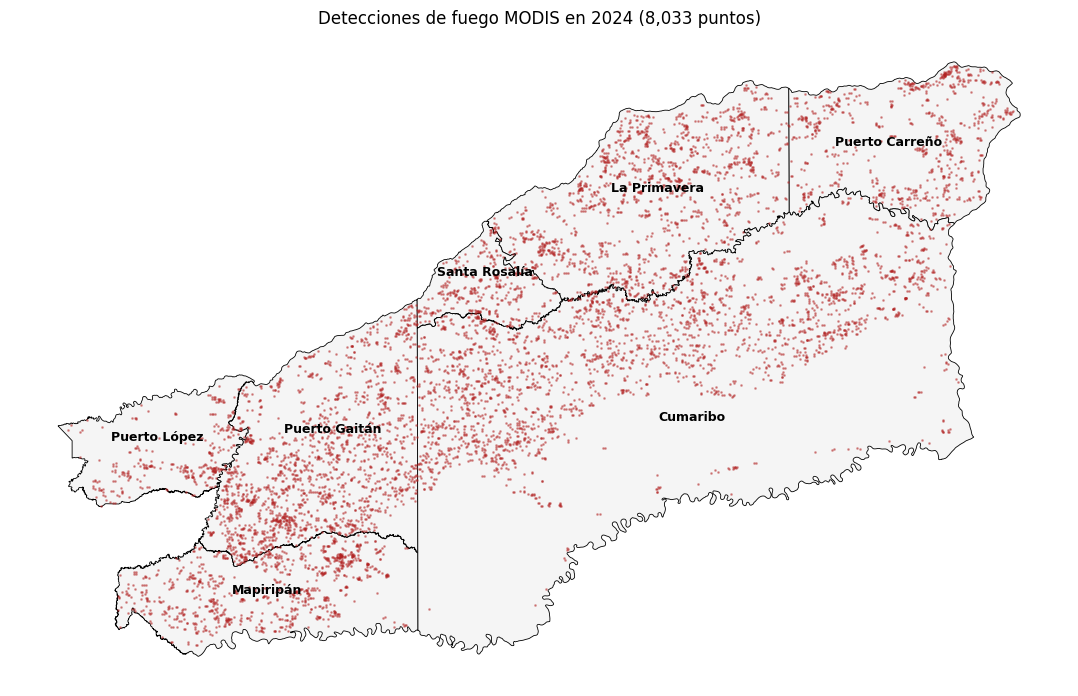

In [ ]:
anio = 2024
pts_anio = puntos[puntos['acq_date'].dt.year == anio]

fig, ax = plt.subplots(figsize=(11, 7))
mpios.plot(ax=ax, color='whitesmoke', edgecolor='black', linewidth=0.6)
pts_anio.plot(ax=ax, markersize=1, color='firebrick', alpha=0.4)

for _, fila in mpios.iterrows():
    p = fila.geometry.representative_point()
    ax.annotate(fila['mpio_cnmbr'].title(), (p.x, p.y),
                ha='center', fontsize=9, fontweight='bold')

ax.set_title(f'Detecciones de fuego MODIS en {anio} ({len(pts_anio):,} puntos)')
ax.set_axis_off()
plt.tight_layout()
plt.savefig(f'{FIGURAS}/03_firms_mapa_{anio}.png', dpi=150)
plt.show()

## Paso 8. Guardar los resultados

In [ ]:
# Puntos filtrados (archivo pesado: se queda en Drive)
cols = ['latitude', 'longitude', 'acq_date', 'acq_time', 'satellite',
        'confidence', 'frp', 'daynight', 'mpio_cdpmp', 'mpio_cnmbr', 'geometry']
salida_pts = puntos[cols].copy()
salida_pts['acq_date'] = salida_pts['acq_date'].dt.strftime('%Y-%m-%d')
salida_pts.to_file(f'{PROCESADOS}/firms_altillanura_puntos.gpkg',
                   layer='focos', driver='GPKG')

# Serie mensual (archivo liviano: se puede subir al repositorio)
salida_mes = mensual.copy()
salida_mes['mes'] = salida_mes['mes'].astype(str)
salida_mes.to_csv(f'{PROCESADOS}/firms_mensual_municipio.csv', index=False)

chk = pd.read_csv(f'{PROCESADOS}/firms_mensual_municipio.csv', dtype={'mpio_cdpmp': str})
print('Guardado OK |', len(chk), 'filas mensuales |',
      chk['mes'].min(), '-', chk['mes'].max())

Guardado OK | 2114 filas mensuales | 2000-11 - 2025-12
